Simulating hodgkin huxley neurons in C++
This is just a quick bit of testing, but may provide a base for an improved version of the simulator

Basic features:
Single compartment conductance based neurons
Voltage and ligand gating 
Simple conductance based synapses

Conductance based neurons:
Resting membrane potential defined in terms of membrane conductances for each ion # Nernst potentials for Na, K, Cl, and Ca, and 
Monoexponential gating defined in terms of Vhalf, Vk, theta0 theta1 sig0 k0



Extra features:
Multicompartments
ChatGPT compile python to c++
Delays
Gap junctions 
Short term plasticity
Long term calcium based plasticity 

In [7]:
import enum
from auxillaryFunctions import *

# build_dir,configType = "build", "Debug"
# moduleDir = os.path.join(build_dir, configType)
# if moduleDir not in sys.path:
#     sys.path.append(moduleDir)

# import cathalTest

#need to map gates to ion channels to neurons
#although if we assume 2 gates per neuron, we can just map gates to neuron 

#we use inverse slope, 1/k, whereas most of the literature uses k. This is because we want to avoid division in the sigmoid function
def genGate(vHalf,vKi,tau0,tau1,th,tkInv,x0=0.0,exponent=1,minOpenness=0):
    return {"x":x0, "vHalf":vHalf,"vKi":vKi,"tau0":tau0,"tau1":tau1,"th":th,"tkInv":tkInv,"exponent":exponent,"minOpenness":minOpenness}

def genOpenGate():
    return genGate(-1000,1000,100,1000,0,0,x0=1)


def genSynapseGate(xt1,TS):
    xt0 = TS
    xt1 = xt1-xt0
    return genGate(0.5,100,xt0,xt1,0.5,-100)


def genDefaultPlasticSynapseData(gain):
    return {
        "efficacy": 0, #p, unitless
        "conductanceGain": gain, #
        "rate": 0.05, #ms
        "gammaP": 0.12, #p per ms
        "gammaD": 0.078, #p per ms
        "thetaP": 0.68, #Ca mol/L
        "thetaD": 0.33, #Ca mol/L
    }

def genAMPA(TS,baseConductance,conductanceGain = 10):
    #for the synapses to work properly you need to know TS
    #This lets the conductance go instantly from 0 to 1
    
    AMPA = {"name":"AMPAR",
                "ion":"Cation",
            "Erev": 0,
            "conductance": baseConductance,
            "current":0,
            "CaCurrent": 0,
            "gates":{
            "vGate1":genOpenGate(),
            "vGate2":genOpenGate(),
            "CaGate":genOpenGate(),
            "spikeGate":genSynapseGate(7,TS)}} #decay is about 7ms for AMPA and GABA, though it can vary a lot, tbh this could be a random variable
    
    for key,val in genDefaultPlasticSynapseData(conductanceGain).items():
        AMPA[key] = val

    return AMPA

def genGABA(TS,baseConductance,conductanceGain):
    GABA = genAMPA(TS,baseConductance,conductanceGain)
    GABA["Erev"] = -80
    return GABA

#is there an automatic way to determine the best way to structure the equatins for GPU
# def addSpikerToSystem(ac,spikerPreNeuron,spikerNeuronScale,spikerProbability):
#     #all the stuff normally realting to neural spiking gets added here
#     ac["spikerPreNeuron"].append(spikerPreNeuron)
#     ac["spikerNeuronScale"].append(spikerNeuronScale) #0 for random, 1 for neuron based
#     ac["spikerProbability"].append(spikerProbability) #set to 0 to remove random spiking

def addSpikerToSystem(ac,spkrDict,spikerPreNeuron):
    #all the stuff normally realting to neural spiking gets added here
    ac["spikerPreNeuron"].append(spikerPreNeuron)
    ac["spikerNeuronScale"].append(spkrDict["spikerNeuronScale"]) #0 for random, 1 for neuron based
    ac["spikerProbability"].append(spkrDict["spikerProbability"]) #set to 0 to remove random spiking

def genChannelData(neuronData,spikerData,synapseData,diffusionList,TS):
    #new keys: spikerPreNeuron, spikerNeuronScale, nSpikers, channelPreSpiker (used to be preNeuron)
    allChannelData = {key:[] for key in genOpenGate().keys()}
    listKeys = ["postNeuron","channelPreSpiker","conductance","Erev","CaCurrent","inputDelay", #channel parameters
                "efficacy","conductanceGain","rate","gammaP","gammaD","thetaP","thetaD", #plasticity parameters
                "diffPostNeuron","diffPreNeuron","diffRate","current","name",#diffusion parameters
                "spikerPreNeuron","spikerNeuronScale","spikerProbability"] #spiker parameters 

    valueKeys = ["nChannels","nDiffusiveConnections","nSpikers","nNeurons"]

    for key in listKeys:
        allChannelData[key] = []
    for key in valueKeys:
        allChannelData[key] = 0

    #efficacy, conductanceGain, rate, gammaP, gammaD, thetaP, thetaD,
    def addDiffusiveConnection(preNeuron,postNeuron,diffusionRate):
        allChannelData["diffPostNeuron"].append(postNeuron)
        allChannelData["diffPreNeuron"].append(preNeuron)
        allChannelData["diffRate"].append(diffusionRate)
        allChannelData["nDiffusiveConnections"]+=1

    nNeurons = len(neuronData)
    allChannelData["nNeurons"] = nNeurons
    nSpikers = 0
    allChannelData["biasCurrents"] = []
    for ind,data in enumerate(neuronData):
        spkrData = data["spikerData"]
        if spkrData is not None:
            addSpikerToSystem(allChannelData,spkrData,ind)
            nSpikers +=1
        allChannelData["biasCurrents"].append(data["neuronData"]["bias"])
        for channel,channelData in data["channelData"].items():
            #if channel not in ["neuronData","spikerData"]: #info about the neuron specifically, separate from the channel
                addBasicChannelToSystem(allChannelData,ind,channelData)

    for spkrData in spikerData:
        addSpikerToSystem(allChannelData,spkrData,0)

    nSpikers +=len(spikerData)
    allChannelData["nSpikers"] = nSpikers
    allChannelData["writeIndex"] = np.zeros(nSpikers,dtype=np.int32)
    maxDelayInt = 1 #default to 1
    for group in synapseGroups:
        for conn in group:
            pre,post = conn["pre"],conn["post"]
            synapseData = conn["synapse"]
            delay = conn["delay"] #in ms
            delayInt = int(np.ceil(delay/TS))
            maxDelayInt = max(delayInt,maxDelayInt)
            assert 0<=pre<nSpikers and 0<=post<nSpikers, f"edge out of range {pre},{post}"
            addSynapseToSystem(pre,post,synapseData,delayInt,allChannelData)


    for (e0,e1,diffusionRate) in diffusionList:
        assert e0<nNeurons and e1<nNeurons, f"edge out of range {e0},{e1}"
        addDiffusiveConnection(e0,e1,diffusionRate)
    
    allChannelData["maxDelayInt"] = maxDelayInt
    allChannelData["voltages"] = -75*np.ones(nNeurons,dtype = np.float32) + 1*np.arange(0,nNeurons,dtype=np.float32)
    allChannelData["calciumVals"] = np.zeros(nNeurons,dtype = np.float32)
    # allChannelData["biasCurrents"] = bias*np.ones(nNeurons,dtype = np.float32)
    allChannelData["spikeVals"] = np.zeros(nSpikers,dtype = np.float32)
    allChannelData["netCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["netCaCurrent"] = np.zeros(nNeurons,dtype = np.float32)
    allChannelData["spikeBuffer"] = np.zeros((nSpikers,maxDelayInt),dtype=bool)

    intKeys = ["channelPreSpiker","postNeuron", "nChannels","diffPostNeuron",
               "diffPreNeuron","nDiffusiveConnections","writeIndex",
               "maxDelayInt","inputDelay","nNeurons","nSpikers","spikerPreNeuron"]
    
    nonArrayKeys = ["nNeurons","maxDelayInt","nChannels","nDiffusiveConnections","name","nSpikers"]
    for key in allChannelData.keys():
        val = allChannelData[key]
        if key in intKeys: arrDtype = np.int32
        else: arrDtype = np.float32

        if key in nonArrayKeys:
            pass
        elif type(val) in [list,tuple]:
            allChannelData[key] = np.ascontiguousarray(val,dtype = arrDtype)
        elif type(val)  == np.ndarray:
            allChannelData[key] = np.ascontiguousarray(val,dtype = val.dtype)
        else:
            print(f"Warning {key} is not a list or tuple") 
    
    return allChannelData


def genSynapseGroup(preRange,postRange,nSynapses,synapse,delay):
    preVals = np.random.randint(preRange[0],preRange[1],nSynapses)
    postVals = np.random.randint(postRange[0],postRange[1],nSynapses)
    synapseData = [{"pre":e0,"post":e1,"synapse":deepcopy(synapse),"delay":delay} for e0,e1 in zip(preVals,postVals)]
    return synapseData


TS = 0.05
nNeurons = 4
k = 2
nSTN = int(nNeurons/3)
nGPe = nNeurons-nSTN
nCTX = 2*nSTN
nMSN = 2*nGPe

STNrange = [0,nSTN]
GPeRange = [nSTN,nNeurons]
CTXrange = [nNeurons,nNeurons+nCTX]
MSNrange = [nNeurons+nCTX,nNeurons+nCTX+nMSN]
nSTN_GPe,nGPe_GPe,nGPe_STN,nCTX_STN,nMSN_GPe = k*nSTN,k*nGPe,k*nGPe,k*nSTN,k*nGPe
STNbias = -2.1
GPeBias = -0.23
np.random.seed(0)
#synapse
STN_GPe = genSynapseGroup(STNrange,GPeRange,nSTN_GPe,genAMPA(TS,baseConductance=0.015,conductanceGain=0),delay=4) #0.02
GPe_GPe = genSynapseGroup(GPeRange,GPeRange,nGPe_GPe,genGABA(TS,baseConductance=0.025,conductanceGain=0),delay=2)
GPe_STN = genSynapseGroup(GPeRange,STNrange,nGPe_STN,genGABA(TS,baseConductance=0.5,conductanceGain=0),delay=4)
CTX_STN = genSynapseGroup(CTXrange,STNrange,nCTX_STN,genAMPA(TS,baseConductance=0.15,conductanceGain=0),delay=0.2)
MSN_GPe = genSynapseGroup(MSNrange,GPeRange,nMSN_GPe,genAMPA(TS,baseConductance=0.02,conductanceGain=0),delay=0.2)

synapseGroups = [STN_GPe,GPe_GPe,GPe_STN,CTX_STN,MSN_GPe] #[STN_GPe,GPe_GPe,GPe_STN]

#neurons
STNchannels = np.load(r"tools\translatedSTNchannels2.npy",allow_pickle=True).item()
GPechannels = np.load(r"tools\translatedGPechannels2.npy",allow_pickle=True).item()

neuronData = []
for _ in range(nSTN):
    STNdata = {}
    STNdata["channelData"] = deepcopy(STNchannels)
    STNdata["neuronData"]={"bias":STNbias}
    STNdata["spikerData"] = {"spikerNeuronScale":1,"spikerProbability":0}
    neuronData.append(STNdata)

for _ in range(nGPe):
    GPeData = {}
    GPeData["channelData"]  = deepcopy(GPechannels)
    GPeData["neuronData"]={"bias":GPeBias}
    GPeData["spikerData"] = {"spikerNeuronScale":1,"spikerProbability":0}
    neuronData.append(GPeData)

CTXprobability,MSNprobability = 0.01,0.001
CTXrate,MSNrate = 3.3,2.1
CTXprobability,MSNprobability = CTXrate*TS/1000,MSNrate*TS/1000

spikerData = []
for _ in range(nCTX):
    spkDict = {"spikerNeuronScale":0,"spikerProbability":CTXprobability}
    spikerData.append(spkDict)

for _ in range(nMSN):
    spkDict = {"spikerNeuronScale":0,"spikerProbability":MSNprobability}
    spikerData.append(spkDict)

diffRate = 1.0
diffusionList = []

allChannelData = genChannelData(neuronData,spikerData,synapseGroups,diffusionList,TS)

#TODO: current stimulation over time by modifying the bias current? or a new current 
#TODO: I think have an overwrite for the bias current, same as spike overwrite
#TODO: think about release goals!!



e:\code\pythonCPPtesting.ipynb\auxillaryFunctions.py:48: RuntimeWarning: overflow encountered in exp
  return minOp +  (1.0-minOp)/(1.0 + np.exp((h-z)*kInv))


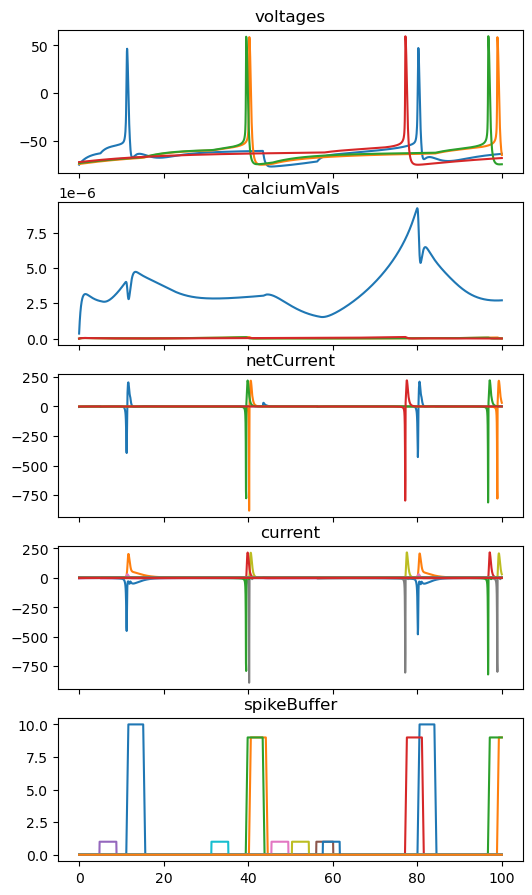

In [8]:
#theres different levels to this, each needs tools for simulating and testing
#channels
#spikers
#single compartment neurons
#multicompartment neurons
#neural populations 
#neural networks

#stimulate all ampa synapses on neuron 0?
#over write the spike output of neuron 1? 
#what you really need to be able to do is inject current into a specific neuron at a specific time point 
#which might mean that for the period of simulation you state exactly what the current value will be at each time point for every neuron 
#very memory inefficient, but might be fast on a gpu
#in python we specify the stimulation with indices and values for when the bias is anything other than the default value 
# bias overwrite as a parameter?

#new keys: spikerPreNeuron, spikerNeuronScale, nSpikers, channelPreSpiker (used to be preNeuron)

def solveNeurons(ac,TS):
    #this function deals with determination of membrane voltage and calcium dynamics, 
    # i have moved spiking dynamics to the solveSpikers function 
    voltage = ac["voltages"]
    nNeurons = ac["nNeurons"]
    calciumVals = ac["calciumVals"]
    alpha = 1/(2*96485) #this is the conversion factor between current and Ca diffusion. scale it up if you want Ca in different units 
    CaEquilibriumVal = 0 #1 I think 1e-6 is reasonble, otsuka is 0
    CaRemovalRate = 2 #ms, this is the value otsuka uses, not sure where they get it from 
    for i in range(nNeurons):
        voltage[i] -= TS*(ac["netCurrent"][i]+ac["biasCurrents"][i])
        calciumVals[i] += TS*(-alpha*ac["netCaCurrent"][i] + (-calciumVals[i]+ CaEquilibriumVal)*CaRemovalRate) #This requires some explaination:
                        #We need to convert Ca current (in uA/cm^2) to Ca concentration (in mol/L) so I hardcode the conversion factor 
                        #Cellular Ca is tightly regulated to ~uM concentrations, so I've included a fixed point at 1e-6.
                        #I've set the timeconstant for Ca regulation to be 0.5ms, which might be a little fast
                        #With this implementation its possible to have 1. calcium efflux (which is fine), and 2. negative Ca concentrations (which is not fine)
                        #but negative Ca would require persistent Vm>140mV which is unphysiological anyway. 



#TODO: neurons have a spike buffer but spikers should also have a very small buffer
#TODO: spikers shouldnt be allowed a full buffer, too expensive
#TODO: neurons shouldnt be allowed have a buffer because some of them might not be axons
#NOTE: Solution. spikers get to have buffers and we will measure the performance impact to see if its significant
        
def solveSpikers(ac,TS):
    writeIndex = ac["writeIndex"]
    spikerPreNeuron = ac["spikerPreNeuron"] #this si the neuron that gets checked 
    spikerNeuronScale = ac["spikerNeuronScale"] #0 or 1
    voltages = ac["voltages"]
    spikeBuffer = ac["spikeBuffer"]
    nSpikers = ac["nSpikers"]
    spikerProbability = ac["spikerProbability"]
    for i in range(nSpikers):
        #randomOutput = bool(np.random.exp(spikerProbability*TS)>thresh) #TODO: actually figure this out
        randomOutput = bool(np.random.random()<spikerProbability[i])
        spikeOutput =  bool(spikerNeuronScale[i]*int(voltages[spikerPreNeuron[i]]>0))  # here we could actually implement transmitter release and short term plasticity dynamics 
        spikeOutput = float(randomOutput or spikeOutput)                      # for now its very simple spike threshold 
        spikeBuffer[i][writeIndex[i]] = spikeOutput         
        writeIndex[i] = (writeIndex[i]+1)%ac["maxDelayInt"]


def solveChannels(ac,spikeOverwriteList,TS):
    nChannels = ac["nChannels"]
    voltage = ac["voltages"]
    calciumVals = ac["calciumVals"]
    writeIndex = ac["writeIndex"]
    maxDelay = ac["maxDelayInt"]

    for i in range(nChannels):
        postSynapticNeuron = ac["postNeuron"][i]
        V = voltage[postSynapticNeuron]
        Ca = calciumVals[postSynapticNeuron]
        preSynapticSpiker = ac["channelPreSpiker"][i] #for channel this is = to postSynaptic neuron, and does not matter
        #spikes = max(spikeVals[preSynapticSpiker],spikeOverwriteList[i])
        xs = ac["x"][i]
        xhs,xks = ac["vHalf"][i],ac["vKi"][i]
        xts0,xts1 = ac["tau0"][i],ac["tau1"][i]
        xths,xtks = ac["th"][i],ac["tkInv"][i]
        
        exponents = ac["exponent"][i]
        minOpenness = ac["minOpenness"][i]
        Erev = ac["Erev"][i]
        g0 = ac["conductance"][i]
        p = ac["efficacy"][i]
        w = ac["conductanceGain"][i]
        CaCurrent = ac["CaCurrent"][i]

        tempTS = TS
        gatingTotal = 1

        for j in range(len(xs)):
            x = xs[j]
            n = exponents[j]
            gatingTotal *= (x**n)

        g = g0 + w*p
        I = g*gatingTotal*(V-Erev) 
        ac["netCurrent"][postSynapticNeuron] += I
        ac["netCaCurrent"][postSynapticNeuron] += CaCurrent*I
        ac["current"][i] = I

        synapseDelay = ac["inputDelay"][i]
        readIndex = int((writeIndex[preSynapticSpiker]-synapseDelay)%maxDelay)
        perceivedSpike = ac["spikeBuffer"][preSynapticSpiker][readIndex]
        perceivedSpike = max(perceivedSpike,spikeOverwriteList[i])

        xs[0] = solveGate(xs[0],V,tempTS,xhs[0],xks[0],xts0[0],xts1[0],xths[0],xtks[0],minOpenness[0]) #gate1
        xs[1] = solveGate(xs[1],V,tempTS,xhs[1],xks[1],xts0[1],xts1[1],xths[1],xtks[1],minOpenness[1]) #gate2
        xs[2] = solveGate(xs[2],Ca,tempTS,xhs[2],xks[2],xts0[2],xts1[2],xths[2],xtks[2],minOpenness[2]) #CaGate
        xs[3] = solveGate(xs[3],perceivedSpike,tempTS,xhs[3],xks[3],xts0[3],xts1[3],xths[3],xtks[3],minOpenness[3]) #spikeGate

        dp = calcWeightChange(p,Ca,ac["rate"][i],ac["gammaP"][i],ac["gammaD"][i],ac["thetaP"][i],ac["thetaD"][i])
        ac["efficacy"][i]+=TS*dp

#TODO: update solveChannels to pull the spike from the correct location, and update genChannelData to provide the correct input 

def solveSystemStandard(ac,TS,runTime,stimInfo={},
                        recordingKeys = ["voltages","calciumVals","netCurrent","current","spikeBuffer"]):
    nIterations = int(runTime/TS)
    data = {key:[] for key in recordingKeys}
    tv = np.linspace(0,runTime,nIterations)
    nNeurons = ac["nNeurons"]
    nChannels = ac["nChannels"]
    for iteration,t in enumerate(tv):   
        #calculate currents
        ac["netCurrent"] = np.zeros([nNeurons])
        ac["netCaCurrent"] = np.zeros([nNeurons])
        spikeOverwriteList = np.zeros(nChannels)
        if iteration in stimInfo.keys():
            for syn in stimInfo[iteration]:
                spikeOverwriteList[syn] = 1

        #update the gates
        solveChannels(ac,spikeOverwriteList,TS)

        solveDiffusiveConnections(ac)

        solveNeurons(ac,TS)

        solveSpikers(ac,TS)

        for key in data:
            data[key].append(deepcopy(ac[key]))

    for key in data:
        data[key] = np.array(data[key])
    data["time"] = tv
    return data


runTime = 100
stimInfo = {}
allChannelDataPy = deepcopy(allChannelData)
data = solveSystemStandard(allChannelDataPy,TS,runTime,stimInfo) 
standardPlot(data)

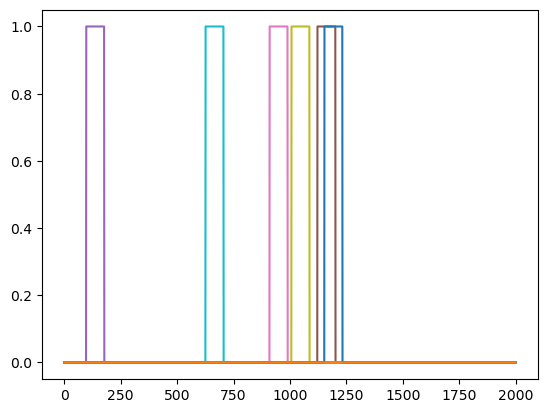

In [5]:
x = data["spikeBuffer"].sum(axis=2)
plt.plot(x);

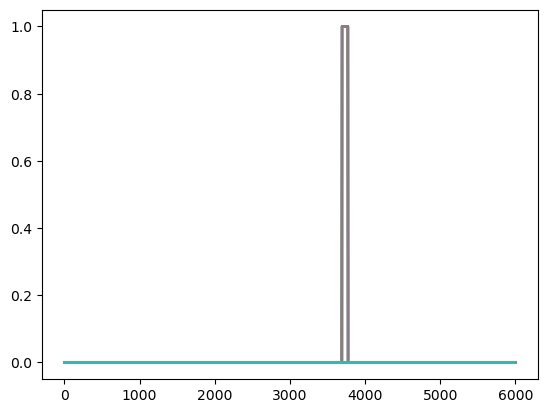

In [54]:
y = data["spikeBuffer"]
plt.plot(y[:,3,:]);

In [35]:
allChannelDataPy["spikerPreNeuron"]

array([0., 1., 2., 3., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [30]:
TS = 0.08
rate = 17.4 #Hz
probability = rate*TS/1000
nSecs = 26
nSamples = int(nSecs*1000*(1/TS))
samps = np.random.random(size=nSamples)

In [31]:
np.sum(samps<probability)/nSecs

17.884615384615383

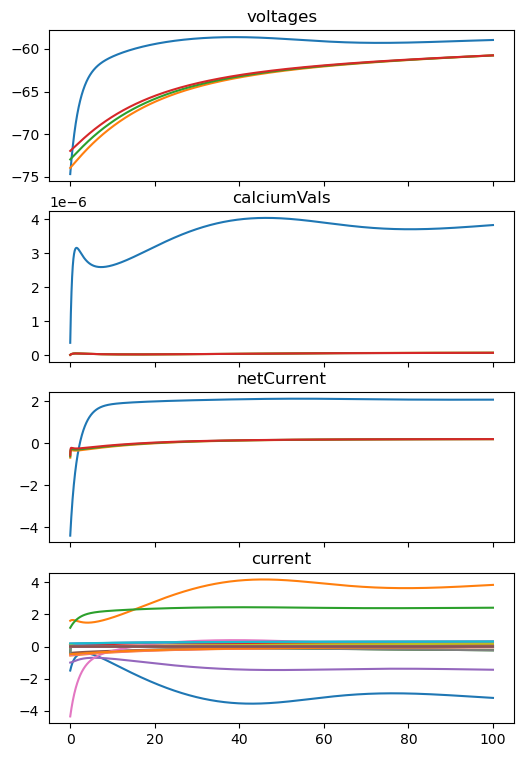

In [4]:
stimInfo = {}

def solveSystemStandard(ac,TS,runTime,stimInfo={},
                        recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    data = {key:[] for key in recordingKeys}
    tv = np.linspace(0,runTime,nIterations)
    nNeurons = ac["nNeurons"]
    nChannels = ac["nChannels"]
    for iteration,t in enumerate(tv):   
        #calculate currents
        ac["netCurrent"] = np.zeros([nNeurons])
        ac["netCaCurrent"] = np.zeros([nNeurons])
        spikeOverwriteList = np.zeros(nChannels)
        if iteration in stimInfo.keys():
            for syn in stimInfo[iteration]:
                spikeOverwriteList[syn] = 1

        #update the gates
        solveChannels(ac,spikeOverwriteList,TS)

        solveDiffusiveConnections(ac)

        solveNeurons(ac,TS)

        for key in data:
            data[key].append(deepcopy(ac[key]))

    for key in data:
        data[key] = np.array(data[key])
    data["time"] = tv
    return data

allChannelDataPy = deepcopy(allChannelData)
data = solveSystemStandard(allChannelDataPy,TS,runTime,stimInfo) 
standardPlot(data)

Elapsed time in seconds: 0.2424107


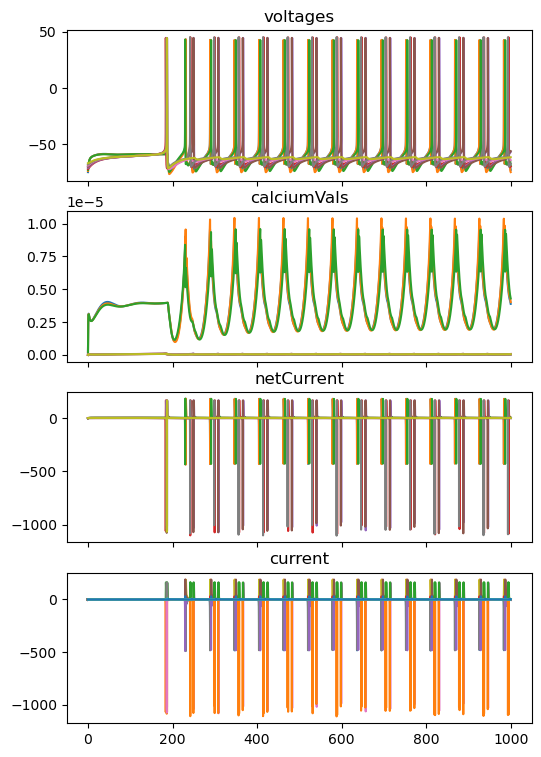

In [126]:

allChannelDataPy = deepcopy(allChannelData)

stimTime = 5
stimInd = int(stimTime/TS)
stimInfo = {}

build_dir,configType = "build", "Debug" ##NOTE: make sure your are using correct version
moduleDir = os.path.join(build_dir, configType)
if moduleDir not in sys.path:
    sys.path.append(moduleDir)

import cathalTest

def solveSystemCpp(ac,TS,runTime,samplingInterval=2, recordingKeys = ["voltages","calciumVals","netCurrent","current"]):
    nIterations = int(runTime/TS)
    nSamples = int(np.ceil(nIterations/samplingInterval))
    
    #data = {key:np.zeros([nSamples] + list(ac[key].shape) ) for key in recordingKeys}
    data = {}
    for key in recordingKeys:
        shape = [nSamples] + list(ac[key].shape)
        data[key] = np.zeros(shape,dtype=np.float32) #np.ascontiguousarray

    tv = np.linspace(0,runTime,nSamples)

    cathalTest.solveNeuralSystem(ac,data,TS,nIterations,samplingInterval)

    data["time"] = tv
    return data



allChannelDataCpp = deepcopy(allChannelData)
dataCpp = solveSystemCpp(allChannelDataCpp,TS,runTime,samplingInterval=1)
#gatingPlotSideBySide(data,dataCpp)
#sideBySidePlot(data,dataCpp)
standardPlot(dataCpp) #5x worse than real time with 100 neurons #
#20 neurons, 1000ms takes 1.27 seconds. n=100, k=5 took 11 seconds for 1 second, 2 second for release version 

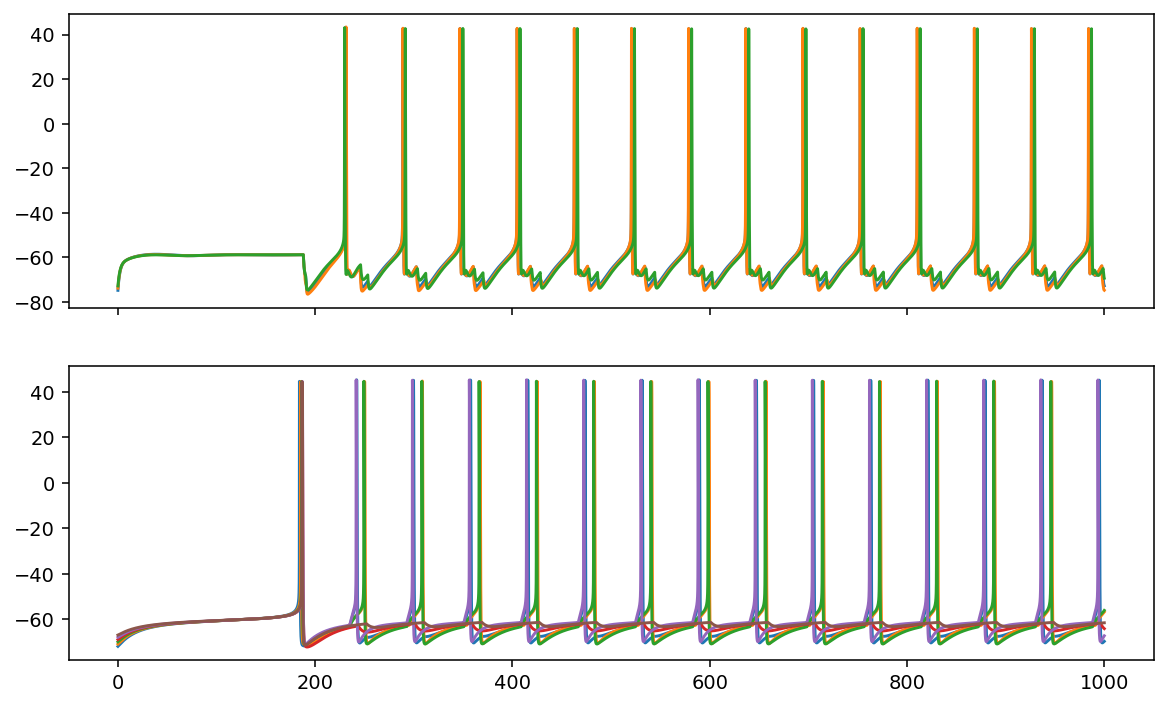

In [127]:
fig,ax = plt.subplots(2,1,figsize=(10,6),dpi=140,sharex=True)
tv = dataCpp["time"]
voltages = dataCpp["voltages"]
ax[0].plot(tv,voltages[:,0:nSTN])
ax[1].plot(tv,voltages[:,nSTN:nNeurons])

In [ ]:
def standardPlot(data,ax=None,ls="-"):
    if ax is None:
        fig,ax = plt.subplots(len(data.keys())-1,1,figsize=(6,1.8*len(data.keys())),dpi=100,sharex=True)
    time = data["time"]
    for i,(key,val) in enumerate(data.items()):
        if key != "time":
            ax[i].set_title(key)
            if len(val.shape)<3:
                ax[i].plot(time,val,ls=ls)
            else:
                ax[i].plot(time,val[:,-1,3],ls=ls)
